**Notebook 02: Interrupted time series (ITS) of generic dapagliflozin share**

This notebook measures how the generic dapagliflozin share of all SGLT2 items changed in each of the three West Midlands ICBs between January 2025 and June 2026, around the start of generic supply in September 2025.

Input: `op_wm_cleaned.csv` (made in notebook 01). Outputs: `ITS_summary.csv`, `ITS_newey_west_results.csv`, `ITS_second_break.csv`, `ITS_results.png` and `ttest_results.csv`. Each run replaces the old versions of these files.

There is no control series, so the results describe change over time. They cannot show what caused the change.

**Step 1: Load libraries**

In [1]:
import importlib
import importlib.util
import subprocess
import sys

required = {'statsmodels': 'statsmodels', 'scipy': 'scipy'}

missing = [pip_name for module, pip_name in required.items()
           if importlib.util.find_spec(module) is None]

if missing:
    print('Installing:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    importlib.invalidate_caches()
else:
    print('All required packages are already installed')

All required packages are already installed


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded')

Libraries loaded


**Step 2: Load the ICB data and create the outcome**

The OpenPrescribing measure gives the share of SGLT2 items that are NOT generic dapagliflozin (`calc_value`). This notebook uses the opposite, the generic share, so that a rising line means more generic prescribing. It is (denominator minus numerator) divided by denominator. The check line confirms this equals 1 minus `calc_value`.

In [3]:
op_wm = pd.read_csv('op_wm_cleaned.csv', parse_dates=['date'])
op_wm['generic_share'] = (op_wm['denominator'] - op_wm['numerator']) / op_wm['denominator']

ICB = {'15E': 'Birmingham and Solihull',
       'B2M3M': 'Coventry and Warwickshire',
       'D2P2L': 'Black Country'}

print('Rows:', op_wm.shape[0])
print(op_wm.groupby('org_name')['date'].agg(['count', 'min', 'max']))
print('Check against 1 - calc_value:', np.allclose(op_wm['generic_share'], 1 - op_wm['calc_value']))

Rows: 54
                               count        min        max
org_name                                                  
NHS BIRMINGHAM AND SOLIHULL       18 2025-01-01 2026-06-01
NHS BLACK COUNTRY                 18 2025-01-01 2026-06-01
NHS COVENTRY AND WARWICKSHIRE     18 2025-01-01 2026-06-01
Check against 1 - calc_value: True


**Step 3: Look at the raw series first**

Before modelling, check the shape of the data. The table shows the generic share (%) at key months. The chart shows all 18 months for the three ICBs.

date                           Jan 2025  Aug 2025  Sep 2025  Mar 2026  \
org_name                                                                
NHS BIRMINGHAM AND SOLIHULL        53.0      56.4      56.4      57.8   
NHS BLACK COUNTRY                  64.6      65.7      65.6      67.5   
NHS COVENTRY AND WARWICKSHIRE      60.8      62.2      62.4      64.1   

date                           Jun 2026  
org_name                                 
NHS BIRMINGHAM AND SOLIHULL        69.7  
NHS BLACK COUNTRY                  76.8  
NHS COVENTRY AND WARWICKSHIRE      65.3  


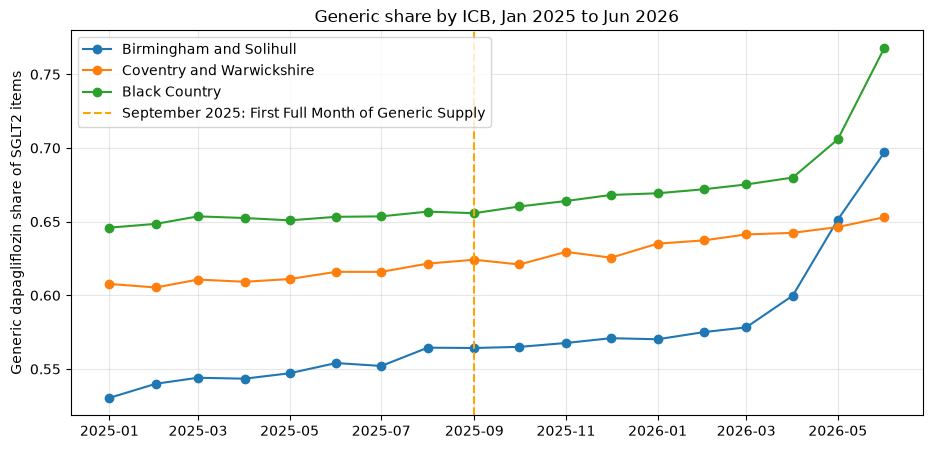

In [4]:
key_months = pd.to_datetime(['2025-01-01', '2025-08-01', '2025-09-01', '2026-03-01', '2026-06-01'])
raw = (op_wm[op_wm['date'].isin(key_months)]
       .pivot(index='org_name', columns='date', values='generic_share'))
raw.columns = raw.columns.strftime('%b %Y')
print((raw * 100).round(1))

fig, ax = plt.subplots(figsize=(11, 5))
for org_id, name in ICB.items():
    d = op_wm[op_wm['org_id'] == org_id].sort_values('date')
    ax.plot(d['date'], d['generic_share'], 'o-', label=name)
ax.axvline(pd.Timestamp('2025-09-01'), color='orange', linestyle='--',
           label='September 2025: First Full Month of Generic Supply')
ax.set_ylabel('Generic dapagliflozin share of SGLT2 items')
ax.set_title('Generic share by ICB, Jan 2025 to Jun 2026')
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

**Step 4: Create the ITS variables**

The model needs three time variables. `time` counts months from 1 (Jan 2025) to 18 (Jun 2026). `post` is 0 up to Aug 2025 and 1 from Sep 2025. `time_after` counts months since September 2025: 0 up to Aug 2025, then 1 for Sep 2025, 2 for Oct 2025 and so on. It equals `time - 8`, with negative values set to 0.

The check line makes sure `post` and `time_after` agree. The table shows the coding for Birmingham and Solihull.

In [5]:
def its_data(org_id):
    d = op_wm[op_wm['org_id'] == org_id].sort_values('date').reset_index(drop=True)
    d['time'] = np.arange(1, len(d) + 1)               # Jan 2025 = 1
    d['post'] = (d['date'] >= '2025-09-01').astype(int)
    d['time_after'] = (d['time'] - 8).clip(lower=0)    # Aug 2025 = 0, Sep 2025 = 1
    assert ((d['time_after'] > 0) == (d['post'] == 1)).all()
    return d

print(its_data('15E')[['date', 'time', 'post', 'time_after', 'generic_share']]
      .round(3).to_string(index=False))

      date  time  post  time_after  generic_share
2025-01-01     1     0           0          0.530
2025-02-01     2     0           0          0.540
2025-03-01     3     0           0          0.544
2025-04-01     4     0           0          0.543
2025-05-01     5     0           0          0.547
2025-06-01     6     0           0          0.554
2025-07-01     7     0           0          0.552
2025-08-01     8     0           0          0.564
2025-09-01     9     1           1          0.564
2025-10-01    10     1           2          0.565
2025-11-01    11     1           3          0.568
2025-12-01    12     1           4          0.571
2026-01-01    13     1           5          0.570
2026-02-01    14     1           6          0.575
2026-03-01    15     1           7          0.578
2026-04-01    16     1           8          0.600
2026-05-01    17     1           9          0.651
2026-06-01    18     1          10          0.697


**Step 5: Fit the ITS model with OLS**

The model is: generic share = constant + b1 x time + b2 x post + b3 x time_after.

b1 is the monthly trend before September 2025. b2 is the step change at September 2025. b3 is the change in the monthly trend after the September 2025 change, called the slope change. One model is fitted for each ICB.

In [6]:
models = {}
for org_id, name in ICB.items():
    d = its_data(org_id)
    X = sm.add_constant(d[['time', 'post', 'time_after']])
    models[org_id] = {'data': d, 'X': X,
                      'ols': sm.OLS(d['generic_share'], X).fit()}
    print('=' * 70)
    print(name)
    print('=' * 70)
    print(models[org_id]['ols'].summary())

Birmingham and Solihull
                            OLS Regression Results                            
Dep. Variable:          generic_share   R-squared:                       0.784
Model:                            OLS   Adj. R-squared:                  0.738
Method:                 Least Squares   F-statistic:                     16.98
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           6.12e-05
Time:                        21:13:09   Log-Likelihood:                 46.275
No. Observations:                  18   AIC:                            -84.55
Df Residuals:                      14   BIC:                            -80.99
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5291      0

**Step 6: Check autocorrelation (Durbin-Watson)**

Monthly data often have residuals that follow each other. A Durbin-Watson value near 2 means little autocorrelation. Values well below 2 mean positive autocorrelation, which makes ordinary OLS standard errors too small.

In [7]:
dw_table = pd.DataFrame({
    'ICB': list(ICB.values()),
    'Durbin-Watson': [durbin_watson(models[k]['ols'].resid) for k in ICB]})
print(dw_table.round(2).to_string(index=False))

                      ICB  Durbin-Watson
  Birmingham and Solihull           0.64
Coventry and Warwickshire           2.73
            Black Country           0.94


**Step 7: Compare standard errors (OLS, HC3 and Newey-West)**

The coefficients are the same in all three versions. Only the standard errors and p-values change. HC3 allows for unequal residual spread. Newey-West (2 lags) also allows for autocorrelation.

With only 18 points, and 8 before September 2025, both robust methods can give standard errors that are too small. None of the three should be treated as the correct one. Results that hold under all three are the safest to report.

In [8]:
for org_id in ICB:
    d, X = models[org_id]['data'], models[org_id]['X']
    y = d['generic_share']
    models[org_id]['hc3'] = sm.OLS(y, X).fit(cov_type='HC3', use_t=True)
    models[org_id]['nw'] = sm.OLS(y, X).fit(
        cov_type='HAC', cov_kwds={'maxlags': 2, 'use_correction': True}, use_t=True)

terms = {'time': 'Slope before Sep 2025',
         'post': 'Level change (Sep 2025)',
         'time_after': 'Slope change'}

rows = []
for org_id, name in ICB.items():
    m = models[org_id]
    for t, label in terms.items():
        rows.append({'ICB': name, 'Term': label,
                     'Coefficient': m['ols'].params[t],
                     'OLS SE': m['ols'].bse[t], 'OLS p': m['ols'].pvalues[t],
                     'HC3 SE': m['hc3'].bse[t], 'HC3 p': m['hc3'].pvalues[t],
                     'NW SE': m['nw'].bse[t], 'NW p': m['nw'].pvalues[t]})

its_table = pd.DataFrame(rows)
print(its_table.round(4).to_string(index=False))

                      ICB                    Term  Coefficient  OLS SE  OLS p  HC3 SE  HC3 p  NW SE   NW p
  Birmingham and Solihull   Slope before Sep 2025       0.0040  0.0032 0.2417  0.0008 0.0002 0.0004 0.0000
  Birmingham and Solihull Level change (Sep 2025)      -0.0331  0.0197 0.1158  0.0228 0.1685 0.0196 0.1140
  Birmingham and Solihull            Slope change       0.0081  0.0040 0.0616  0.0049 0.1217 0.0041 0.0687
Coventry and Warwickshire   Slope before Sep 2025       0.0020  0.0004 0.0002  0.0005 0.0023 0.0003 0.0000
Coventry and Warwickshire Level change (Sep 2025)      -0.0020  0.0024 0.4267  0.0036 0.5965 0.0017 0.2745
Coventry and Warwickshire            Slope change       0.0014  0.0005 0.0144  0.0007 0.0687 0.0004 0.0048
            Black Country   Slope before Sep 2025       0.0012  0.0025 0.6472  0.0003 0.0038 0.0002 0.0001
            Black Country Level change (Sep 2025)      -0.0219  0.0154 0.1761  0.0172 0.2227 0.0133 0.1223
            Black Country            

**Step 8: Summary table and gap at June 2026**

The gap is the difference at June 2026 between the fitted line from September 2025 and the earlier trend continued forward. June 2026 is 10 on the `time_after` scale, so the gap is b2 + 10 x b3. It is shown in percentage points, with a p-value under each of the three standard error methods.

In [9]:
summary_rows = []
for org_id, name in ICB.items():
    m = models[org_id]
    d = m['data']
    tests = {k: m[k].t_test('post + 10*time_after = 0') for k in ['ols', 'hc3', 'nw']}
    summary_rows.append({
        'ICB': name,
        'Share Jan 2025 (%)': d['generic_share'].iloc[0] * 100,
        'Share Jun 2026 (%)': d['generic_share'].iloc[-1] * 100,
        'R-squared': m['ols'].rsquared,
        'Durbin-Watson': durbin_watson(m['ols'].resid),
        'Gap at Jun 2026 (pp)': float(np.squeeze(tests['ols'].effect)) * 100,
        'Gap p (OLS)': float(np.squeeze(tests['ols'].pvalue)),
        'Gap p (HC3)': float(np.squeeze(tests['hc3'].pvalue)),
        'Gap p (NW)': float(np.squeeze(tests['nw'].pvalue))})

its_summary = pd.DataFrame(summary_rows)
print(its_summary.round(3).to_string(index=False))

                      ICB  Share Jan 2025 (%)  Share Jun 2026 (%)  R-squared  Durbin-Watson  Gap at Jun 2026 (pp)  Gap p (OLS)  Gap p (HC3)  Gap p (NW)
  Birmingham and Solihull              53.040              69.698      0.784          0.644                 4.774        0.317        0.149       0.086
Coventry and Warwickshire              60.774              65.303      0.975          2.734                 1.158        0.058        0.140       0.012
            Black Country              64.592              76.793      0.733          0.943                 5.307        0.161        0.067       0.016


**Step 9: Plot observed, fitted and the trend before September 2025**

The grey dotted line shows where the trend before September 2025 would have gone. The shaded area marks Apr to Jun 2026, where the sharpest rises occur. The chart is saved as `ITS_results.png`.

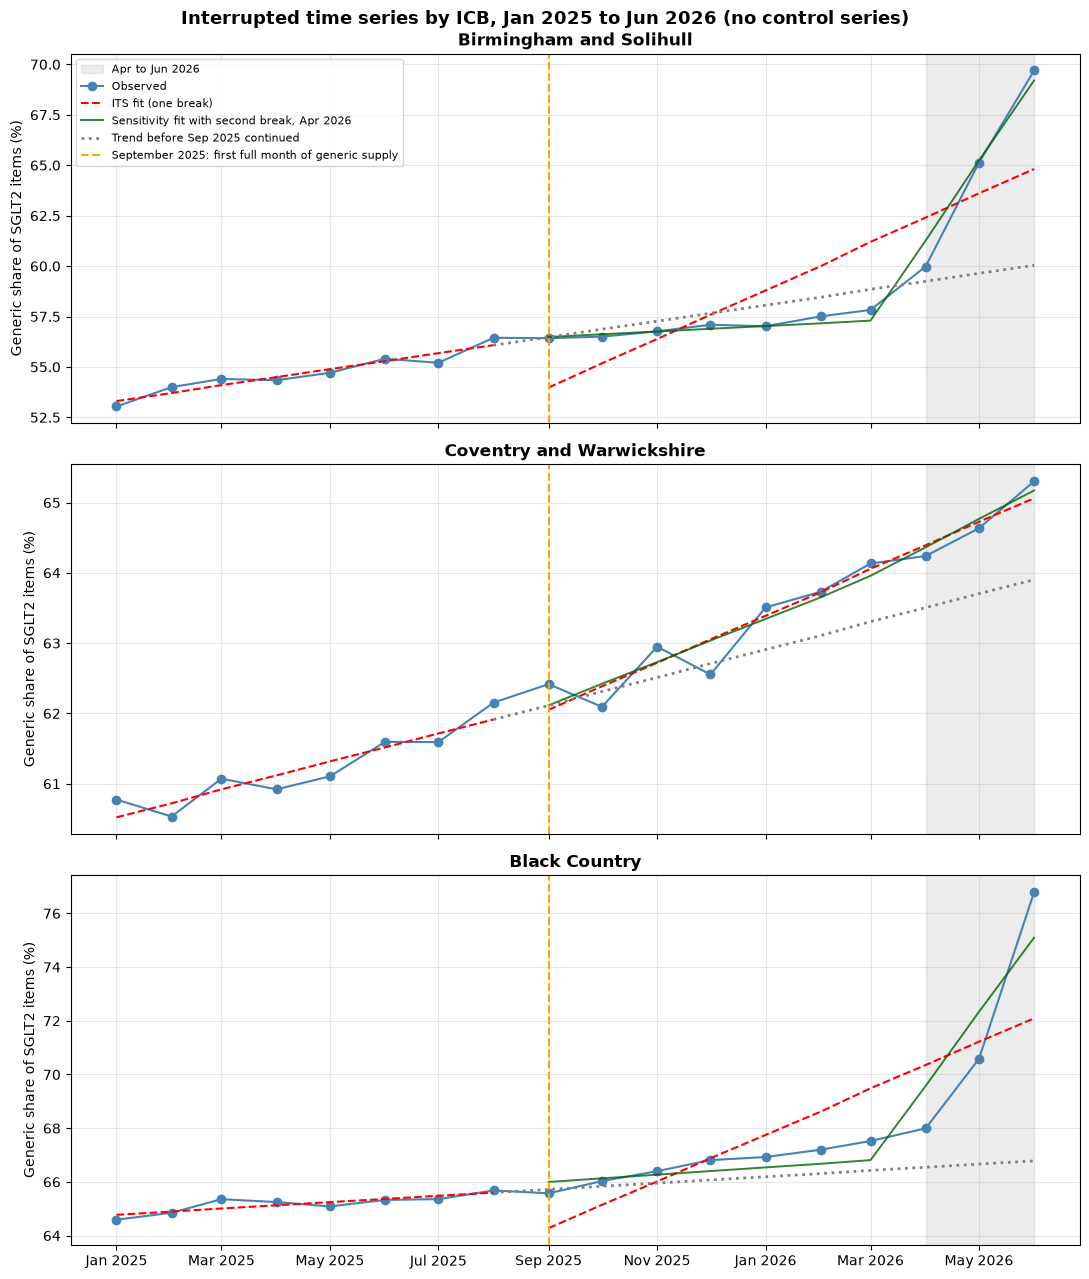

In [10]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(3, 1, figsize=(11, 13), sharex=True)
for k, (ax, (org_id, name)) in enumerate(zip(axes, ICB.items())):
    d = models[org_id]['data'].copy()
    ols = models[org_id]['ols']
    y = d['generic_share'] * 100                       # plot in %
    fit = ols.fittedvalues * 100
    trend = (ols.params['const'] + ols.params['time'] * d['time']) * 100

    # Two-break sensitivity fit (same model as Step 11, second slope change from Apr 2026)
    d['time_after2'] = (d['time'] - 15).clip(lower=0)  # Apr 2026 = 1
    X2 = sm.add_constant(d[['time', 'post', 'time_after', 'time_after2']])
    fit2 = sm.OLS(d['generic_share'], X2).fit().fittedvalues * 100

    pre, post = d['post'] == 0, d['post'] == 1
    ax.axvspan(pd.Timestamp('2026-04-01'), pd.Timestamp('2026-06-01'),
               color='grey', alpha=0.15, label='Apr to Jun 2026')
    ax.plot(d['date'], y, 'o-', color='steelblue', label='Observed')
    ax.plot(d['date'][pre], fit[pre], '--', color='red')
    ax.plot(d['date'][post], fit[post], '--', color='red', label='ITS fit (one break)')
    ax.plot(d['date'][post], fit2[post], '-', color='darkgreen', linewidth=1.4, alpha=0.8,
            label='Sensitivity fit with second break, Apr 2026')
    ax.plot(d['date'][d['time'] >= 8], trend[d['time'] >= 8], ':', color='grey', linewidth=2,
            label='Trend before Sep 2025 continued')
    ax.axvline(pd.Timestamp('2025-09-01'), color='orange', linestyle='--',
               label='September 2025: first full month of generic supply')
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Generic share of SGLT2 items (%)')
    ax.grid(True, alpha=0.3)
    if k == 0:
        ax.legend(fontsize=8, loc='upper left')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.suptitle('Interrupted time series by ICB, Jan 2025 to Jun 2026 (no control series)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('ITS_results.png', dpi=300, bbox_inches='tight')
plt.show()

**Step 10: Sensitivity check, data to March 2026 only**

The sharpest changes are in the last three months. This step refits the model without Apr to Jun 2026 to see how much of the slope change depends on those months. With 15 points the estimates are rough, so use this as a check and not as a main result.

In [11]:
sens_rows = []
for org_id, name in ICB.items():
    d = its_data(org_id)
    d = d[d['date'] <= '2026-03-01']
    X = sm.add_constant(d[['time', 'post', 'time_after']])
    short = sm.OLS(d['generic_share'], X).fit()
    full = models[org_id]['ols']
    sens_rows.append({'ICB': name,
                      'Slope change (18 months)': full.params['time_after'],
                      'p (OLS)': full.pvalues['time_after'],
                      'Slope change (to Mar 2026)': short.params['time_after'],
                      'p (OLS) to Mar 2026': short.pvalues['time_after'],
                      'Months used': len(d)})

sensitivity = pd.DataFrame(sens_rows)
print(sensitivity.round(4).to_string(index=False))

                      ICB  Slope change (18 months)  p (OLS)  Slope change (to Mar 2026)  p (OLS) to Mar 2026  Months used
  Birmingham and Solihull                    0.0081   0.0616                     -0.0016               0.0271           15
Coventry and Warwickshire                    0.0014   0.0144                      0.0012               0.0945           15
            Black Country                    0.0075   0.0298                      0.0019               0.0004           15


**Step 11: Sensitivity check, a second slope change from April 2026**

Step 10 shows that the last three months drive much of the slope change. This step models that directly. It adds a second slope change from April 2026 (`time_after2`, 1 in April 2026 and 3 in June 2026), where the raw series in Step 3 turns upward in two ICBs. Only three months follow April 2026, so the result is read as a check on the shape of the series and not as a separate test.

In [12]:
BREAK2 = '2026-04-01'

rows2 = []
for org_id, name in ICB.items():
    d = its_data(org_id)
    t2 = int(d.loc[d['date'] == BREAK2, 'time'].iloc[0])        # 16
    d['time_after2'] = (d['time'] - (t2 - 1)).clip(lower=0)     # Apr 2026 = 1
    X = sm.add_constant(d[['time', 'post', 'time_after', 'time_after2']])
    y = d['generic_share']
    fits = {'OLS': sm.OLS(y, X).fit(),
            'HC3': sm.OLS(y, X).fit(cov_type='HC3', use_t=True),
            'NW': sm.OLS(y, X).fit(cov_type='HAC',
                                   cov_kwds={'maxlags': 2, 'use_correction': True},
                                   use_t=True)}
    one_break = models[org_id]['ols']
    for term, label in [('post', 'Level change (Sep 2025)'),
                        ('time_after', 'Slope change (Sep 2025)'),
                        ('time_after2', 'Extra slope change (Apr 2026)')]:
        row = {'ICB': name, 'Term': label,
               'Coefficient (pp)': fits['OLS'].params[term] * 100}
        for k, f in fits.items():
            row[f'{k} p'] = f.pvalues[term]
        rows2.append(row)
    rows2.append({'ICB': name, 'Term': 'Model fit',
                  'Adj R2 one break': one_break.rsquared_adj,
                  'Adj R2 two breaks': fits['OLS'].rsquared_adj,
                  'DW two breaks': durbin_watson(fits['OLS'].resid)})

second_break = pd.DataFrame(rows2)
print(second_break.round(4).to_string(index=False))

                      ICB                          Term  Coefficient (pp)  OLS p  HC3 p   NW p  Adj R2 one break  Adj R2 two breaks  DW two breaks
  Birmingham and Solihull       Level change (Sep 2025)            0.2712 0.6030 0.5892 0.3565               NaN                NaN            NaN
  Birmingham and Solihull       Slope change (Sep 2025)           -0.2604 0.0399 0.1003 0.0073               NaN                NaN            NaN
  Birmingham and Solihull Extra slope change (Apr 2026)            3.8325 0.0000 0.0000 0.0000               NaN                NaN            NaN
  Birmingham and Solihull                     Model fit               NaN    NaN    NaN    NaN            0.7383             0.9860         2.3533
Coventry and Warwickshire       Level change (Sep 2025)           -0.1060 0.7041 0.8120 0.5802               NaN                NaN            NaN
Coventry and Warwickshire       Slope change (Sep 2025)            0.1084 0.1001 0.2448 0.0500               NaN      

**Step 12: Before and after comparison (t-test)**

This compares the mean generic share before and after September 2025, using independent samples (Welch t-test). It is descriptive only. The months are not independent, and the share was already rising before the September 2025 change, so this must not be read as a test of the effect of the September 2025 change.

In [13]:
tt_rows = []
for org_id, name in ICB.items():
    d = its_data(org_id)
    pre = d.loc[d['post'] == 0, 'generic_share']
    post = d.loc[d['post'] == 1, 'generic_share']
    t_stat, p_value = stats.ttest_ind(post, pre, equal_var=False)
    tt_rows.append({'ICB': name,
                    'Mean Jan to Aug 2025': pre.mean(),
                    'Mean Sep 2025 to Jun 2026': post.mean(),
                    'Difference (later minus earlier)': post.mean() - pre.mean(),
                    't-statistic': t_stat,
                    'p-value': p_value})

ttest_df = pd.DataFrame(tt_rows)
print(ttest_df.round(4).to_string(index=False))

                      ICB  Mean Jan to Aug 2025  Mean Sep 2025 to Jun 2026  Difference (later minus earlier)  t-statistic  p-value
  Birmingham and Solihull                0.5469                     0.5939                            0.0470       3.2165   0.0091
Coventry and Warwickshire                0.6122                     0.6356                            0.0234       6.1562   0.0000
            Black Country                0.6519                     0.6818                            0.0300       2.8322   0.0192


**Step 13: Save results**

This saves the summary table, the side by side standard error table, the second-break check and the t-test results. The chart was saved in Step 9. These replace the old files with the same names. `ITS_newey_west_results.csv` now holds the OLS, HC3 and Newey-West results together.

In [14]:
its_summary.to_csv('ITS_summary.csv', index=False)
its_table.to_csv('ITS_newey_west_results.csv', index=False)
second_break.to_csv('ITS_second_break.csv', index=False)
ttest_df.to_csv('ttest_results.csv', index=False)

print('Saved: ITS_summary.csv, ITS_newey_west_results.csv, ITS_second_break.csv,')
print('       ITS_results.png, ttest_results.csv')

Saved: ITS_summary.csv, ITS_newey_west_results.csv, ITS_second_break.csv,
       ITS_results.png, ttest_results.csv


**Acknowledgement of AI assistance**

This notebook was written by Mifta Mahmood with assistance from Claude (Anthropic), a generative AI assistant, which helped to write and debug the code. All code was run, checked and verified by the author, and the outputs shown are from the author's own runs. The final decisions on data, methods and interpretation are the author's own.